In [1]:
import numpy as np
import matplotlib.pyplot as plt
from starter_pack.code import utils
from filters_helpers import to_gray
from pyramids import (
    reduce,
    expand,
    build_gaussian_pyramid,
    build_laplacian_pyramid,
    reconstruct_laplacian_pyramid
)

In [2]:
img_raw = utils.load_image("mosque.jpg")

img = img_raw[:407, :611]
print(f"Working image shape (non-power of 2): {img.shape}")

Working image shape (non-power of 2): (407, 611, 3)


In [3]:
num_levels = 4
G_pyr = build_gaussian_pyramid(img, levels=num_levels)
L_pyr = build_laplacian_pyramid(G_pyr)

print("Gaussian Pyramid level shapes:")
for idx, g in enumerate(G_pyr):
    print(f"  Level {idx}: {g.shape}")

Gaussian Pyramid level shapes:
  Level 0: (407, 611, 3)
  Level 1: (204, 306, 3)
  Level 2: (102, 153, 3)
  Level 3: (51, 77, 3)
  Level 4: (26, 39, 3)


In [4]:
img_rebuilt = reconstruct_laplacian_pyramid(L_pyr)
error_map = np.abs(img - img_rebuilt)
max_error = np.max(error_map)

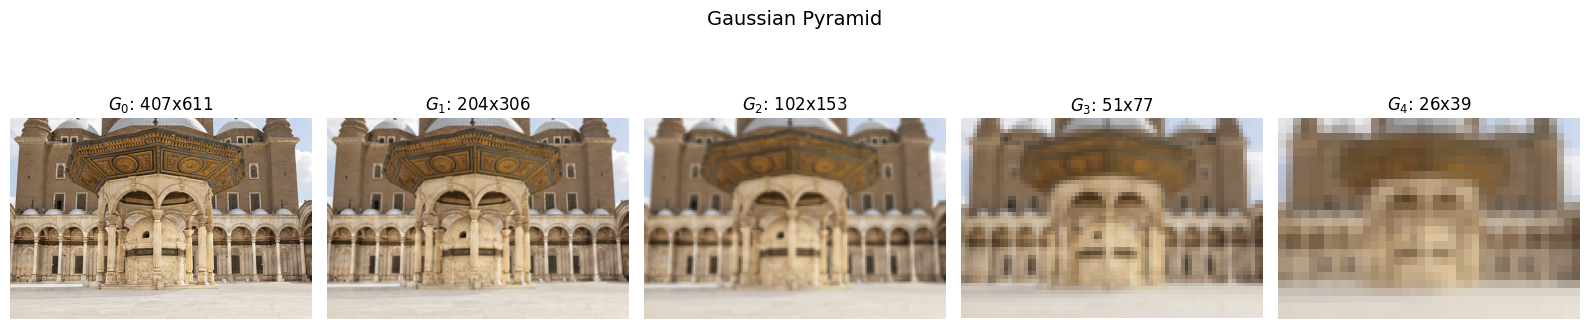

In [5]:
fig, axes = plt.subplots(1, len(G_pyr), figsize=(16, 4))
for i, (ax, g) in enumerate(zip(axes, G_pyr)):
    ax.imshow(np.clip(g, 0, 1), cmap="gray" if g.ndim == 2 else None)
    ax.set_title(f"$G_{i}$: {g.shape[0]}x{g.shape[1]}")
    ax.axis("off")
plt.suptitle("Gaussian Pyramid", fontsize=14)
plt.tight_layout()
plt.show()

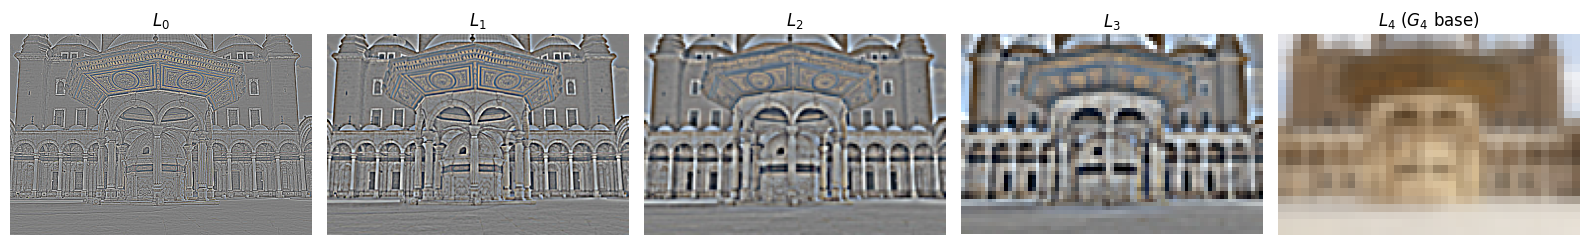

In [6]:
fig, axes = plt.subplots(1, len(L_pyr), figsize=(16, 4))
for i, (ax, l) in enumerate(zip(axes, L_pyr)):
    if i == len(L_pyr) - 1:
        disp = np.clip(l, 0, 1)
    else:
        disp = np.clip(l * 3.0 + 0.5, 0, 1)
        
    ax.imshow(disp, cmap="gray" if disp.ndim == 2 else None)
    ax.set_title(f"$L_{i}$" if i < len(L_pyr)-1 else f"$L_{i}$ ($G_{i}$ base)")
    ax.axis("off")
plt.tight_layout()
plt.show()

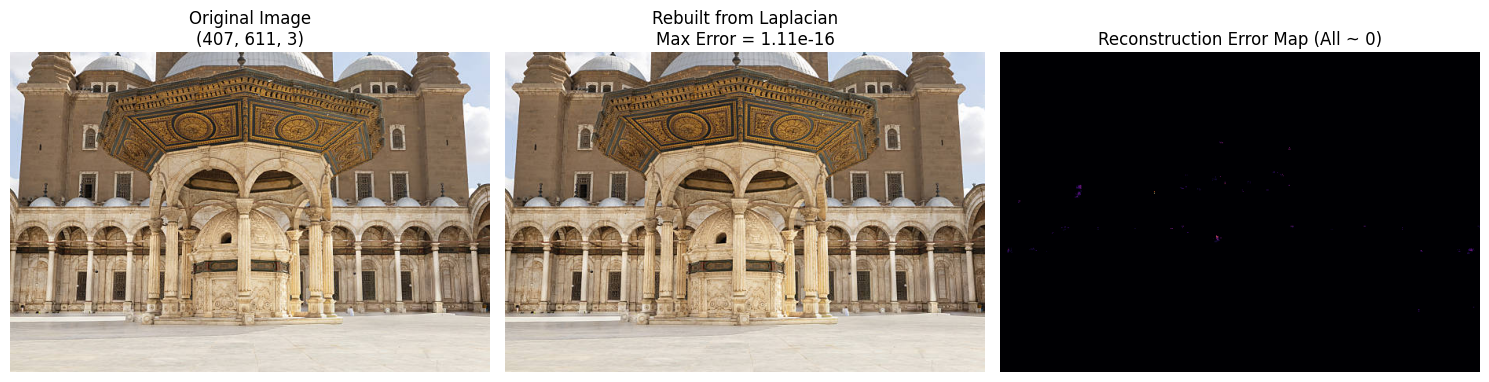

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(np.clip(img, 0, 1), cmap="gray" if img.ndim == 2 else None)
axes[0].set_title(f"Original Image\n{img.shape}")
axes[0].axis("off")

axes[1].imshow(np.clip(img_rebuilt, 0, 1), cmap="gray" if img_rebuilt.ndim == 2 else None)
axes[1].set_title(f"Rebuilt from Laplacian\nMax Error = {max_error:.2e}")
axes[1].axis("off")

axes[2].imshow(error_map if error_map.ndim == 2 else error_map.mean(axis=-1), cmap="inferno")
axes[2].set_title("Reconstruction Error Map")
axes[2].axis("off")

plt.tight_layout()
plt.show()